# **TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos**

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos.

El entrenamiento se realiza en Colab para aprovechar la GPU.

Requisitos previos (en tu fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

Al finalizar:
- Descargar los checkpoints generados y colocarlos en `models/` del entorno local
  (la aplicación los usa en las pestañas de las Etapas 1, 2 y 3).
- Publicarlos en un link público de solo lectura para los docentes.

**Notebook en Google Colab:** https://colab.research.google.com/github/luciajaureguiheisterborg-eng/tuia-dog-recognition-app/blob/feature%2Ftp2-razas-perros/2-train.ipynb#scrollTo=5f1d16a3


## Equipo
- Alumno 1 : Jauregui, Lucía
- Alumno 2 : Nebbia, Maria Sofía

## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [8]:
REPO_URL = "https://github.com/luciajaureguiheisterborg-eng/tuia-dog-recognition-app.git"
!git clone -b feature/tp2-razas-perros $REPO_URL proyecto
%cd proyecto

Cloning into 'proyecto'...
remote: Enumerating objects: 226, done.
remote: Counting objects: 100% (226/226), done.
remote: Compressing objects: 100% (141/141), done.
remote: Total 226 (delta 128), reused 168 (delta 82), pack-reused 0 (from 0)
Receiving objects: 100% (226/226), 10.51 MiB | 11.59 MiB/s, done.
Resolving deltas: 100% (128/128), done.
/content/proyecto/proyecto


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [9]:
!pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [10]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data/dataset
GPU disponible: True


In [ ]:
import copy, json, logging
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from torch.utils.data import DataLoader

from lib.bootstrap import build_classifier, build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.preprocessing import eval_transform
from lib.schemas import Neighbor
from lib.services.classifier_service import BreedDataset

logging.basicConfig(level=logging.INFO, force=True)  # muestra el progreso por época

## 4. Dataset y splits

Descargar el dataset y cargar los splits y el conjunto independiente definidos en
`1-pre-processing.ipynb`.

In [13]:
!python scripts/download_dataset.py
!ls data

Descargando gpiosenka/70-dog-breedsimage-data-set ...
Using Colab cache for faster access to the '70-dog-breedsimage-data-set' dataset.
Dataset disponible en /content/proyecto/proyecto/data/dataset
dataset  embeddings.json  splits.csv


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

**Qué se evalúa.** Un buscador de imágenes por similitud: dada una foto, recupera las 10 imágenes más parecidas de una galería y predice la raza con un voto ponderado por la similitud de esos vecinos.

**Diseño de la evaluación.**
- **Galería:** las 7.487 imágenes de `train`. Es lo único que se indexa.
- **Consultas:** las imágenes de `test` (698) y, más adelante, el conjunto independiente. Ninguna está en la galería, así que no hay fuga de datos.
- **Embeddings:** salida de ResNet18 preentrenada en ImageNet, sin la capa final (512 dimensiones), con el mismo preprocesamiento que usa la app.
- **Búsqueda:** sin base de datos; los embeddings se guardan en una matriz de `numpy` y la búsqueda es un producto matricial.

**Métricas.**
- **NDCG@10** con relevancia binaria (un vecino es relevante si es de la misma raza que la consulta). El ranking ideal se calcula con la cantidad real de imágenes de esa raza en la galería, para que un solo acierto no dé NDCG = 1.
- **Precision@10:** fracción de los 10 vecinos que son de la raza correcta.
- **Accuracy:** porcentaje de consultas donde la raza predicha es la correcta.

**Qué se compara.** Métrica `cosine` vs `l2`, el valor de `TOP_K` y el umbral `SIMILARITY_THRESHOLD`. El umbral se calibra con `valid`, no con `test`.

### 5.1 Preparación: datos y funciones auxiliares

In [20]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
K = 10

splits = pd.read_csv("data/splits.csv")
galeria = splits[splits.split == "train"].reset_index(drop=True)
valid = splits[splits.split == "valid"].reset_index(drop=True)
test = splits[splits.split == "test"].reset_index(drop=True)
print("Galería:", len(galeria), "| valid:", len(valid), "| test:", len(test))


@torch.no_grad()
def embed_paths(paths, embed_fn, root=None, batch_size=64):
    """Embeddings SIN normalizar de una lista de imágenes, por lotes y en GPU.
    Usa el mismo eval_transform que la app (BGR -> RGB, padding, resize, normalización)."""
    root = root or settings.dataset_path
    ds = BreedDataset(root, list(paths), [0] * len(paths), eval_transform(settings.image_size))
    out = [embed_fn(x.to(DEVICE)).cpu().numpy().astype(np.float32)
           for x, _ in DataLoader(ds, batch_size=batch_size, num_workers=2)]
    return np.concatenate(out)


def evaluar(G, g_breeds, Q, q_breeds, metric="cosine", k=K, threshold=None):
    """NDCG@k, precision@k y accuracy de la raza predicha (voto ponderado del servicio).
    G, Q: embeddings sin normalizar de galería y consultas."""
    g_breeds, q_breeds = np.asarray(g_breeds), np.asarray(q_breeds)
    if metric == "cosine":
        Gn = G / np.linalg.norm(G, axis=1, keepdims=True)
        Qn = Q / np.linalg.norm(Q, axis=1, keepdims=True)
        sims = Qn @ Gn.T
    else:  # l2: similitud = 1 / (1 + distancia), igual que el servicio
        d2 = (Q ** 2).sum(1)[:, None] + (G ** 2).sum(1)[None, :] - 2 * Q @ G.T
        sims = 1.0 / (1.0 + np.sqrt(np.maximum(d2, 0)))
    top = np.argsort(-sims, axis=1)[:, :k]
    n_rel = pd.Series(g_breeds).value_counts().to_dict()  # imágenes de cada raza en la galería

    old = similarity.similarity_threshold
    if threshold is not None:
        similarity.similarity_threshold = threshold
    ndcgs, precs, preds = [], [], []
    try:
        for i in range(len(Q)):
            rel = (g_breeds[top[i]] == q_breeds[i]).astype(float)
            ndcgs.append(ndcg_at_k(rel, k=k, n_relevant=n_rel.get(q_breeds[i], 0)))
            precs.append(rel.mean())
            vecinos = [Neighbor(path=str(j), breed=str(g_breeds[j]), score=float(sims[i, j])) for j in top[i]]
            preds.append(similarity.predict_breed_from_neighbors(vecinos)[0])
    finally:
        similarity.similarity_threshold = old
    preds = np.array(preds)
    return {"ndcg@10": float(np.mean(ndcgs)), "precision@10": float(np.mean(precs)),
            "accuracy": float((preds == q_breeds).mean()),
            "sin_respuesta": float((preds == "unknown").mean()), "_preds": preds, "_top": top, "_sims": sims}

Galería: 7487 | valid: 684 | test: 698


### 5.2 Embeddings del baseline (ResNet18 de ImageNet)

In [21]:
similarity = build_similarity(settings, build_store(settings))
base = copy.deepcopy(similarity._get_backbone()).to(DEVICE).eval()   # copia en GPU; el servicio sigue en CPU

E_gal = embed_paths(galeria.path, base)
E_val = embed_paths(valid.path, base)
E_test = embed_paths(test.path, base)
print("Embeddings:", E_gal.shape, E_val.shape, E_test.shape)

# Control: el cálculo por lotes coincide con similarity.extract_embedding (el que usa la app)
img = cv2.imread(str(settings.dataset_path / galeria.path[0]))
ref = np.array(similarity.extract_embedding(img))
mio = E_gal[0] / np.linalg.norm(E_gal[0])
print("Diferencia máxima con extract_embedding:", float(np.abs(ref - mio).max()))

INFO:lib.bootstrap:Using JSON file vector store
INFO:lib.services.similarity_service:Loading baseline embedding model: ResNet18 (ImageNet)


Embeddings: (7487, 512) (684, 512) (698, 512)
Diferencia máxima con extract_embedding: 3.785294981767384e-07


### 5.3 Comparación de métricas de similitud: cosine vs l2

In [22]:
filas = {}
for metrica in ("cosine", "l2"):
    r = evaluar(E_gal, galeria.breed, E_test, test.breed, metric=metrica, threshold=0.0)
    filas[metrica] = {m: v for m, v in r.items() if not m.startswith("_")}
res_test = pd.DataFrame(filas).T.round(4)
res_test

,ndcg@10,precision@10,accuracy,sin_respuesta
cosine,0.8726,0.8595,0.9370,0.0
l2,0.8564,0.8413,0.9298,0.0


### 5.4 Efecto de TOP_K

In [23]:
filas = {}
for k in (1, 3, 5, 10, 20):
    r = evaluar(E_gal, galeria.breed, E_test, test.breed, metric="cosine", k=k, threshold=0.0)
    filas[k] = {"ndcg@k": r["ndcg@10"], "precision@k": r["precision@10"], "accuracy": r["accuracy"]}
pd.DataFrame(filas).T.rename_axis("TOP_K").round(4)

,ndcg@k,precision@k,accuracy
TOP_K,,,
1,0.9255,0.9255,0.9255
3,0.9053,0.8992,0.9370
5,0.8926,0.8831,0.9427
10,0.8726,0.8595,0.9370
20,0.8440,0.8254,0.9327


### 5.5 Calibración del umbral de similitud con valid

In [24]:
filas = {}
for t in (0.0, 0.5, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85):
    r = evaluar(E_gal, galeria.breed, E_val, valid.breed, threshold=t)
    respondidas = r["_preds"] != "unknown"
    filas[t] = {"cobertura": respondidas.mean(),
                "accuracy_si_responde": (r["_preds"][respondidas] == valid.breed.to_numpy()[respondidas]).mean(),
                "accuracy_total": r["accuracy"]}
tabla_umbral = pd.DataFrame(filas).T.rename_axis("umbral").round(4)
tabla_umbral

,cobertura,accuracy_si_responde,accuracy_total
umbral,,,
0.00,1.000,0.9386,0.9386
0.50,1.000,0.9386,0.9386
0.60,1.000,0.9386,0.9386
0.65,1.000,0.9386,0.9386
0.70,1.000,0.9386,0.9386
0.75,1.000,0.9386,0.9386
0.80,1.000,0.9386,0.9386
0.85,0.943,0.9442,0.8904


#### Refinamiento del umbral (zona 0,80 a 0,90)

In [25]:
filas = {}
for t in (0.80, 0.82, 0.84, 0.86, 0.88, 0.90):
    r = evaluar(E_gal, galeria.breed, E_val, valid.breed, threshold=t)
    respondidas = r["_preds"] != "unknown"
    filas[t] = {"cobertura": respondidas.mean(),
                "accuracy_si_responde": (r["_preds"][respondidas] == valid.breed.to_numpy()[respondidas]).mean(),
                "accuracy_total": r["accuracy"]}
pd.DataFrame(filas).T.rename_axis("umbral").round(4)

,cobertura,accuracy_si_responde,accuracy_total
umbral,,,
0.80,1.0000,0.9386,0.9386
0.82,0.9927,0.9396,0.9327
0.84,0.9708,0.9428,0.9152
0.86,0.8933,0.9476,0.8465
0.88,0.7398,0.9565,0.7076
0.90,0.4898,0.9522,0.4664


### 5.6 Ejemplos de consultas y sus Top-10

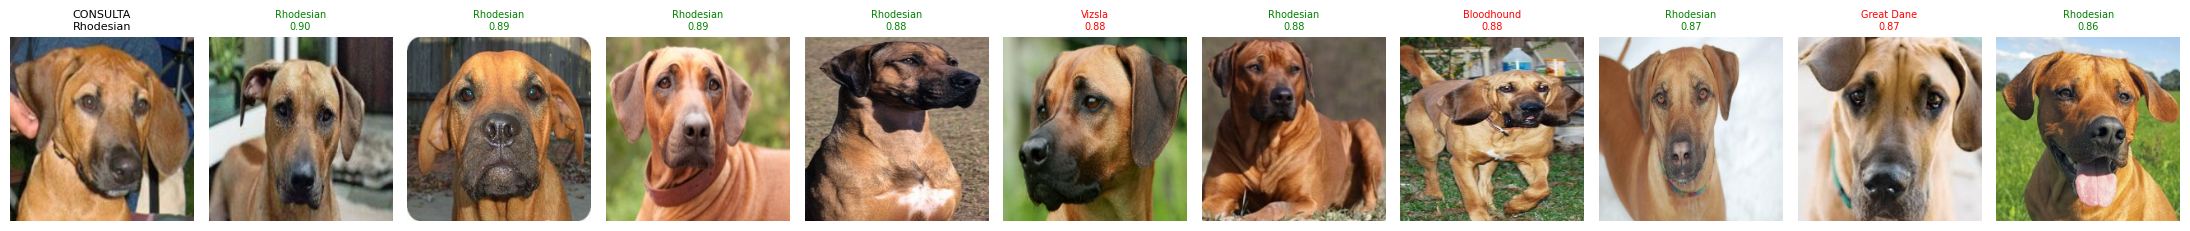

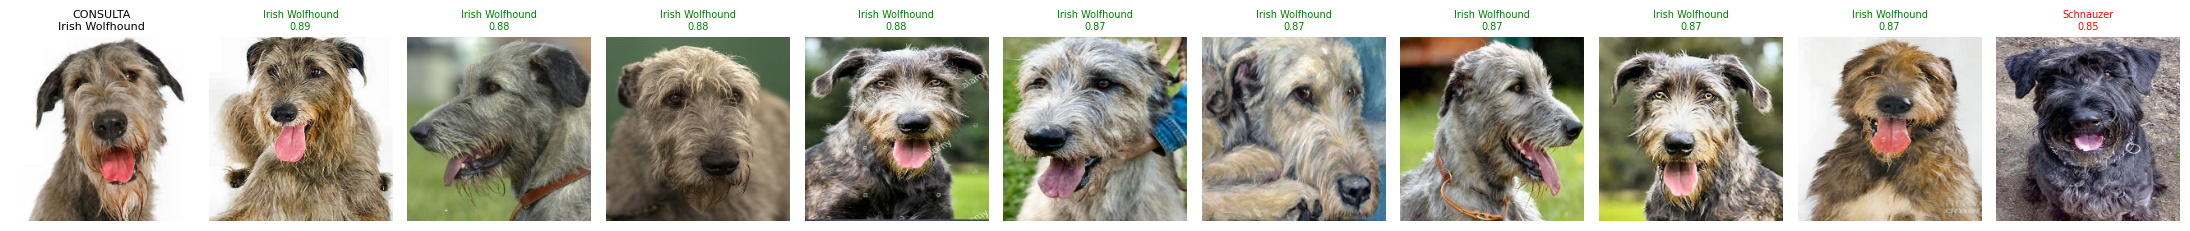

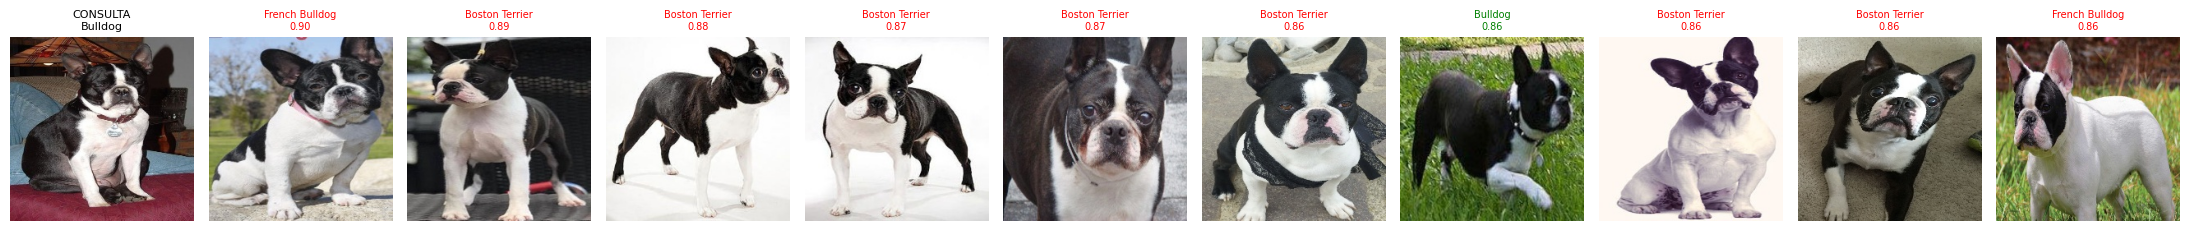

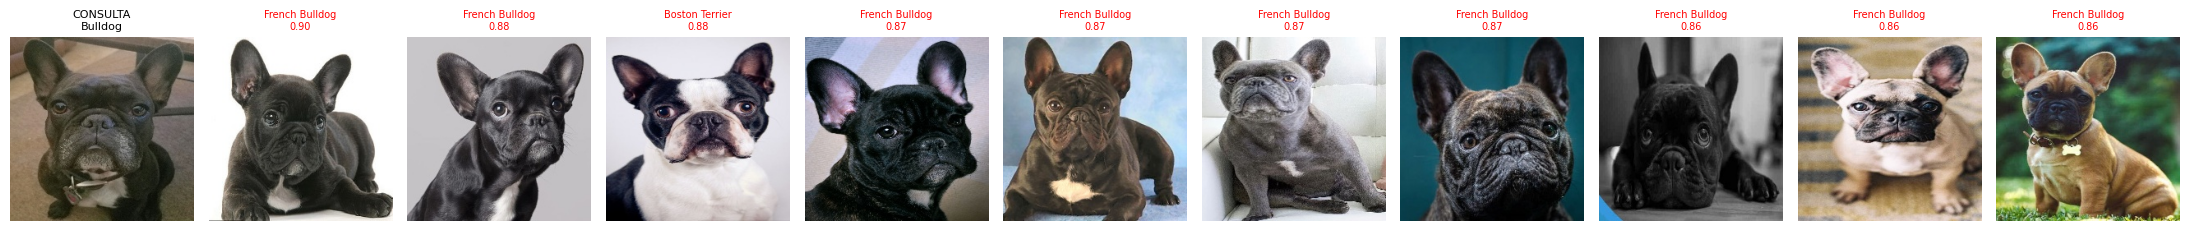

In [26]:
def leer_rgb(ruta):
    return cv2.cvtColor(cv2.imread(str(settings.dataset_path / ruta)), cv2.COLOR_BGR2RGB)


def mostrar_consulta(i, k=10):
    """Imagen de test y sus k vecinos de la galería (verde = misma raza, rojo = otra raza)."""
    r = evaluar(E_gal, galeria.breed, E_test[i:i + 1], test.breed.iloc[i:i + 1], k=k, threshold=0.0)
    top, sims = r["_top"][0], r["_sims"][0]
    fig, ejes = plt.subplots(1, k + 1, figsize=(2 * (k + 1), 2.8))
    ejes[0].imshow(leer_rgb(test.path.iloc[i]))
    ejes[0].set_title(f"CONSULTA\n{test.breed.iloc[i]}", fontsize=8)
    for a, j in zip(ejes[1:], top):
        ok = galeria.breed[j] == test.breed.iloc[i]
        a.imshow(leer_rgb(galeria.path[j]))
        a.set_title(f"{galeria.breed[j]}\n{sims[j]:.2f}", fontsize=7, color="green" if ok else "red")
    for a in ejes:
        a.axis("off")
    plt.tight_layout(); plt.show()


r = evaluar(E_gal, galeria.breed, E_test, test.breed, threshold=0.0)
aciertos = np.where(r["_preds"] == test.breed.to_numpy())[0]
errores = np.where(r["_preds"] != test.breed.to_numpy())[0]
rng = np.random.default_rng(0)
elegidas = list(rng.choice(aciertos, 2, replace=False)) + list(rng.choice(errores, min(2, len(errores)), replace=False))
for i in elegidas:
    mostrar_consulta(int(i))

## 6. Modelo A (obligatorio): fine-tuning de ResNet18

**Modelo.** ResNet18 preentrenada en ImageNet, sin su capa final, con una cabeza nueva (Dropout 0,3 + capa lineal de 512 a 70 razas). El embedding es la salida del backbone (penúltima capa, 512 dimensiones). `train_classifier` guarda el modelo completo, junto con la lista de razas, en `models/resnet18_finetuned.pth`.

**Estrategias comparadas** (se eligen mirando `valid`, no `test`):
1. **Feature extraction:** el backbone queda congelado (incluidas las estadísticas de BatchNorm) y solo se entrena la cabeza. Learning rate 1e-3, hasta 10 épocas.
2. **Fine-tuning completo:** se entrena toda la red con *learning rate diferencial*: 1e-4 para el backbone, que ya sabe extraer rasgos y solo necesita ajustarse, y 1e-3 para la cabeza nueva, que parte de cero. Hasta 15 épocas.

**Hiperparámetros comunes.**
- Optimizador AdamW con weight decay 1e-4.
- Scheduler: CosineAnnealingLR (el learning rate baja suavemente hasta casi 0 a lo largo de las épocas).
- Batch size 64, imágenes de 224 × 224, semilla 42.
- Pérdida: entropía cruzada con **pesos por clase** inversos a la frecuencia (por el desbalance: de 61 a 187 imágenes de train por raza) y *label smoothing* de 0,1.
- Regularización: Dropout 0,3, weight decay y data augmentation solo en train (recorte aleatorio, volteo horizontal, rotación hasta 15°, variaciones de brillo y contraste, desenfoque y ruido gaussiano).
- **Early stopping** con paciencia (3 en feature extraction, 4 en fine-tuning) sobre la accuracy de `valid`, y se conserva el checkpoint de la mejor época.

**Preprocesamiento.** El mismo pipeline en entrenamiento, evaluación y app (BGR a RGB, padding cuadrado con el color medio de ImageNet, resize y normalización ImageNet).

### 6.1 Preparación del servicio de clasificación y Estrategia 1: feature extraction

In [17]:
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.hparams_override = {"resnet18_finetuned": {
    "strategy": "feature_extraction", "epochs": 10, "patience": 3, "tag": "feature_extraction"}}
classifier.train_classifier()
m_fe = classifier.evaluate_classifier(split="valid")
print("Feature extraction (valid):", m_fe)

Feature extraction (valid): {'accuracy': 0.9429824561403509, 'precision': 0.9509852239264003, 'recall': 0.9434920634920636, 'specificity': 0.9991735355533576, 'f1': 0.9413815541009645, 'n_images': 684}


### 6.2 Estrategia 2: fine-tuning completo con learning rate diferencial

In [18]:
logging.basicConfig(level=logging.INFO, force=True)

classifier.hparams_override = {"resnet18_finetuned": {"strategy": "fine_tuning", "tag": "fine_tuning"}}
classifier.train_classifier()
m_ft = classifier.evaluate_classifier(split="valid")
print("Fine-tuning (valid):", m_ft)

INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 1/15 | train loss 2.263 acc 0.571 | valid loss 0.570 acc 0.886 | 50s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 2/15 | train loss 1.362 acc 0.835 | valid loss 0.356 acc 0.942 | 100s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 3/15 | train loss 1.239 acc 0.884 | valid loss 0.319 acc 0.923 | 154s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 4/15 | train loss 1.151 acc 0.915 | valid loss 0.340 acc 0.950 | 204s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 5/15 | train loss 1.101 acc 0.935 | valid loss 0.297 acc 0.947 | 254s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 6/15 | train loss 1.053 acc 0.951 | valid loss 0.294 acc 0.953 | 302s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch 7/15 | train loss 1.018 acc 0.962 | valid loss 0.297 acc 0.959 | 351s
INFO:lib.services.classifier_service:[resnet18_finetuned] epoch

Fine-tuning (valid): {'accuracy': 0.9678362573099415, 'precision': 0.9688492063492066, 'recall': 0.9679365079365078, 'specificity': 0.999533826323144, 'f1': 0.9676393364363288, 'n_images': 684}


### 6.4 Comparación de estrategias (valid)

In [31]:
pd.DataFrame({"feature_extraction": m_fe, "fine_tuning": m_ft}).T.round(4)

,accuracy,precision,recall,specificity,f1,n_images
feature_extraction,0.9430,0.9510,0.9435,0.9992,0.9414,684.0
fine_tuning,0.9678,0.9688,0.9679,0.9995,0.9676,684.0


In [29]:
drive.mount("/content/drive") #Guardado de checkpoints en Drive
!mkdir -p /content/drive/MyDrive/dt_razas/modelos
!cp -r models/*.pth output/*_history.json /content/drive/MyDrive/dt_razas/modelos/
!ls -lh /content/drive/MyDrive/dt_razas/modelos/

Mounted at /content/drive
total 43M
-rw------- 1 root root 2.1K Nov 21 12:48 resnet18_finetuned_feature_extraction_history.json
-rw------- 1 root root 2.9K Nov 21 12:48 resnet18_finetuned_fine_tuning_history.json
-rw------- 1 root root  43M Nov 21 12:48 resnet18_finetuned.pth


**Resultado.** El fine-tuning completo supera a la extracción de rasgos en todas las métricas de `valid`: accuracy 0,968 contra 0,943 y F1 0,968 contra 0,941. Adaptar también los rasgos del backbone, y no solo la capa final, aporta unos 2,5 puntos de accuracy. Se elige **fine-tuning** como Modelo A.

### 6.6 Curvas de entrenamiento y validación


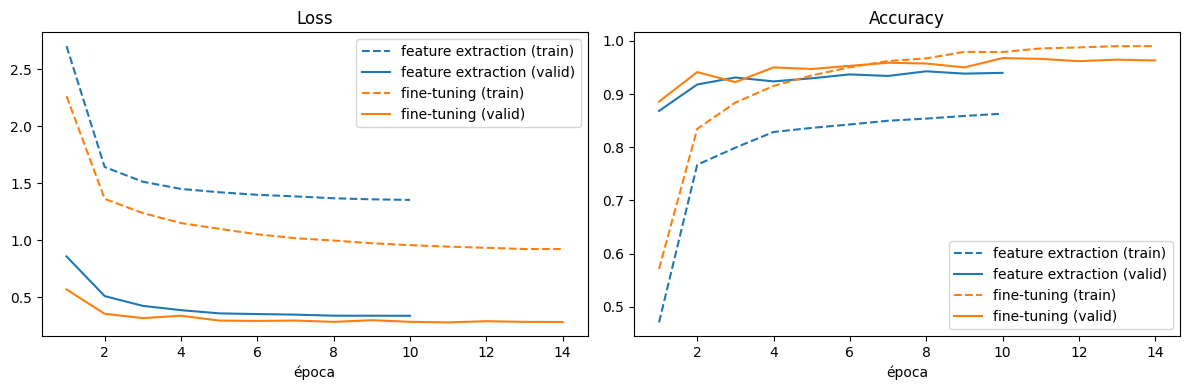

In [32]:
def historia(tag):
    return pd.DataFrame(json.load(open(f"output/resnet18_finetuned_{tag}_history.json"))["history"])

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for tag, nombre in (("feature_extraction", "feature extraction"), ("fine_tuning", "fine-tuning")):
    h = historia(tag)
    l1, = ejes[0].plot(h.epoch, h.train_loss, "--", label=f"{nombre} (train)")
    ejes[0].plot(h.epoch, h.val_loss, color=l1.get_color(), label=f"{nombre} (valid)")
    l2, = ejes[1].plot(h.epoch, h.train_acc, "--", label=f"{nombre} (train)")
    ejes[1].plot(h.epoch, h.val_acc, color=l2.get_color(), label=f"{nombre} (valid)")
ejes[0].set(title="Loss", xlabel="época"); ejes[1].set(title="Accuracy", xlabel="época")
ejes[0].legend(); ejes[1].legend(); plt.tight_layout(); plt.show()

**Lectura de las curvas.** En feature extraction la accuracy de train (0,86) es menor que la de valid (0,94): en train se aplica data augmentation, pesos por clase y label smoothing, que hacen la tarea más difícil, y con el backbone congelado la red tiene poca capacidad para ajustarse. En fine-tuning la accuracy de train supera a la de valid a partir de la época 7 y llega a 0,99, mientras que la de valid se estabiliza entre 0,96 y 0,97 desde la época 10. Esa brecha de unos 2,5 puntos indica un sobreajuste leve; el early stopping corta en la época 14 y conserva el checkpoint de la época 10. La loss de train es más alta que la de valid porque incluye los pesos de clase y el label smoothing, y en valid se mide la entropía cruzada simple.

### 6.7 Evaluación final en test del modelo elegido

In [27]:
metrics_a = classifier.evaluate_classifier()
metrics_a

{'accuracy': 0.9598853868194842,
 'precision': 0.9624855699855701,
 'recall': 0.9596825396825399,
 'specificity': 0.999418634787766,
 'f1': 0.9592063715438328,
 'n_images': 698}

### 6.8 Matriz de confusión y pares de razas más confundidos

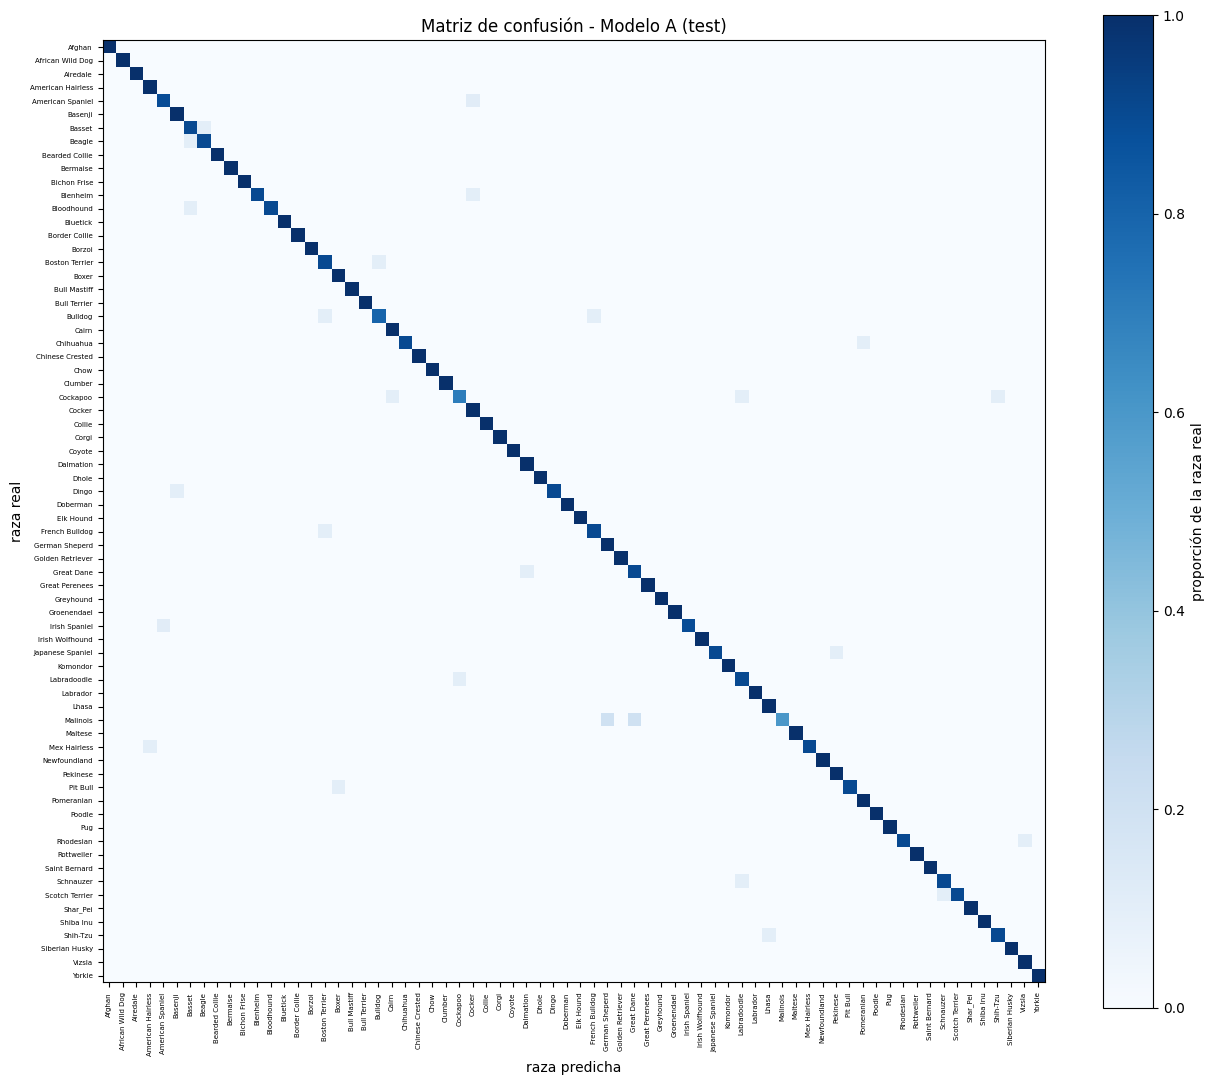

,veces,raza real,predicha como
0,2,Malinois,Great Dane
1,2,Malinois,German Sheperd
2,1,Shih-Tzu,Lhasa
3,1,Scotch Terrier,Schnauzer
4,1,Schnauzer,Labradoodle
5,1,Rhodesian,Vizsla
6,1,Pit Bull,Boxer
7,1,Mex Hairless,American Hairless
8,1,Labradoodle,Cockapoo
9,1,Japanese Spaniel,Pekinese


In [33]:
ev = classifier.last_eval
cm, clases = ev["confusion_matrix"], ev["classes"]
cmn = cm / cm.sum(1, keepdims=True).clip(1)
plt.figure(figsize=(13, 11))
plt.imshow(cmn, cmap="Blues", vmin=0, vmax=1); plt.colorbar(label="proporción de la raza real")
plt.xticks(range(len(clases)), clases, rotation=90, fontsize=5)
plt.yticks(range(len(clases)), clases, fontsize=5)
plt.xlabel("raza predicha"); plt.ylabel("raza real"); plt.title("Matriz de confusión - Modelo A (test)")
plt.tight_layout(); plt.show()

fuera = cm.copy(); np.fill_diagonal(fuera, 0)
pares = sorted(((int(fuera[i, j]), clases[i], clases[j])
                for i in range(len(clases)) for j in range(len(clases)) if fuera[i, j] > 0), reverse=True)[:10]
pd.DataFrame(pares, columns=["veces", "raza real", "predicha como"])

**Resultado en test (698 imágenes).** accuracy 0,960, precision 0,962, recall 0,960, F1 0,959 y specificity 0,999. La caída respecto de `valid` (0,968) es menor a un punto, lo que indica que la selección hecha sobre `valid` no sobreajustó. La specificity es casi 1 por construcción: con 70 razas, cada una tiene 69 clases negativas, por lo que no distingue entre modelos; las métricas informativas son precision, recall y F1. El modelo comete unos 28 errores en 698 imágenes, y están muy repartidos: ningún par de razas se confunde más de 2 veces. Las confusiones más frecuentes son de Malinois (con German Shepherd y con Great Dane, 2 veces cada una); el resto ocurre una sola vez entre razas de aspecto parecido (Shih-Tzu con Lhasa, Mex Hairless con American Hairless, Japanese Spaniel con Pekinese, Labradoodle con Cockapoo). Que Malinois y German Shepherd se confundan es razonable por su parecido físico, pero es una hipótesis que se analiza en la sección 10.

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` debe guardar el checkpoint en
`models/cnn_custom.pth` (o el nombre configurado en `CNN_CUSTOM_MODEL_NAME`).
Definí la arquitectura en un módulo importable (por ejemplo, `src/lib/models/cnn_custom.py`):
si la clase vive en la notebook, `torch.load` falla en la app.

TO-DO: documentar la arquitectura (capas, parámetros, dimensión del embedding), los
hiperparámetros y la tabla de experimentos.

In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
metrics_b

### Curvas de entrenamiento y matriz de confusión (Modelo B)

In [ ]:
## TO-DO: curvas de entrenamiento y matriz de confusión del Modelo B.

## 8. Evaluación sobre el conjunto independiente

TO-DO: las mismas métricas sobre el conjunto independiente para ambos modelos. Comparar con `test`
y discutir el cambio de dominio.

In [ ]:
## TO-DO: métricas de ambos modelos sobre el conjunto independiente.

## 9. Embeddings de los modelos entrenados

TO-DO:
- NDCG@10 de la Etapa 1 con los embeddings del baseline, del Modelo A y del Modelo B
  (`classifier.extract_custom_embedding`), con la misma galería y las mismas consultas.
- Visualización PCA o t-SNE de los embeddings de `test` de cada modelo, lado a lado y coloreada
  por raza (con un subconjunto de razas).

In [ ]:
## TO-DO: NDCG@10 por modelo de embeddings y visualización PCA / t-SNE.

## 10. Análisis de errores

TO-DO: ejemplos de falsos positivos y falsos negativos con la imagen y su score, razas con peor
desempeño e hipótesis sobre las causas.

In [ ]:
## TO-DO: análisis de errores con ejemplos visuales.

## 11. Costo computacional

TO-DO: cantidad de parámetros, tamaño en MB, tiempo de inferencia por imagen en CPU y dimensión
del embedding de cada modelo.

In [ ]:
## TO-DO: costo computacional de cada modelo.

## 12. Comparación y elección final

TO-DO:
- Tabla comparativa de todas las métricas (Modelo A, Modelo B y baseline en la Etapa 1).
- Qué modelo usa la app para clasificar (Etapas 2 y 3) y qué embeddings para la búsqueda
  (`EMBEDDING_MODEL`), con su justificación.
- Búsqueda por similitud vs. clasificación supervisada: ventajas, limitaciones y cuándo conviene cada una.
- Trade-offs entre precisión, velocidad de inferencia, memoria y complejidad.

In [ ]:
## TO-DO: tabla comparativa final.

## 13. Descargar los checkpoints

Descargalos y colocalos en `models/` de tu entorno local para que la aplicación los use.
Recordá publicarlos en un link público de solo lectura y ponerlo en el README y en el PR.

In [ ]:
!ls -lh models/

try:
    from google.colab import files

    files.download(str(settings.model_path / settings.resnet18_model_name))
    files.download(str(settings.model_path / settings.cnn_custom_model_name))
except ImportError:
    print("Fuera de Colab: los checkpoints quedan en models/")